In [15]:
import geass
from rdkit.Chem.Draw import rdMolDraw2D
import networkx as nx
import time
import pandas as pd
from urllib import parse
from rdkit import Chem
from rdkit.Chem.PandasTools import LoadSDF
import re
from rdkit.Chem import rdChemReactions as Reactions
import ipycytoscape
import pickle
allChars = '0123456789abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ'
print('Networkx version :', nx.__version__)

Networkx version : 2.2


In [16]:
with open('../recap-delivery/data/BUL_names.pkl', 'rb') as f:
    BULnames = pickle.load(f)

RuntimeError: Pre-condition Violation
	Number of atom mismatch
	Violation occurred on line 601 in file Code/GraphMol/ROMol.cpp
	Failed Expression: conf->getNumAtoms() == this->getNumAtoms()
	RDKIT: 2019.03.2
	BOOST: 1_68


In [8]:
indexer = pd.read_csv('data/MIBIG-UniqueIDs-ref.csv', encoding='windows-1252')
indexer = {idx:file for idx, file in zip(indexer['Unique_Comp_ID'].values, indexer['File_Name'].values)}
indexer

{'MBC_00001': 'NPA018239.sdf',
 'MBC_00002': 'NPA014300.sdf',
 'MBC_00003': 'NPA010580.sdf',
 'MBC_00004': 'NPA01119.sdf',
 'MBC_00005': 'NPA017529.sdf',
 'MBC_00006': 'NPA02171.sdf',
 'MBC_00007': 'NPA011087.sdf',
 'MBC_00008': 'NPA03386.sdf',
 'MBC_00009': 'NPA04454.sdf',
 'MBC_00010': 'NPA013714.sdf',
 'MBC_00011': 'NPA016469.sdf',
 'MBC_00012': 'NPA012054.sdf',
 'MBC_00013': 'NPA017893.sdf',
 'MBC_00014': 'NPA01724.sdf',
 'MBC_00015': 'NPA019749.sdf',
 'MBC_00016': 'NPA0955.sdf',
 'MBC_00017': 'NPA016676.sdf',
 'MBC_00018': 'NPA03301.sdf',
 'MBC_00019': 'NPA014992.sdf',
 'MBC_00020': 'NPA013831.sdf',
 'MBC_00021': 'NPA08448.sdf',
 'MBC_00022': 'NPA07411.sdf',
 'MBC_00023': 'NPA09354.sdf',
 'MBC_00024': 'NPA019946.sdf',
 'MBC_00025': 'NPA013913.sdf',
 'MBC_00026': 'NPA012274.sdf',
 'MBC_00027': 'NPA01238.sdf',
 'MBC_00028': 'NPA019693.sdf',
 'MBC_00029': 'NPA0326.sdf',
 'MBC_00030': 'NPA02610.sdf',
 'MBC_00031': 'NPA019666.sdf',
 'MBC_00032': 'NPA01579.sdf',
 'MBC_00033': 'NPA011246

In [4]:
# Open the .sdf and .mols
mibig = {}
for idx, file in indexer.items():
    if file.endswith('.sdf'):
        sdf_filename = 'data/sdfs/' + file
        df = LoadSDF(sdf_filename, smilesName='SMILES')
        mibig[idx] = df['ROMol'].values[0]
        
    elif file.endswith('.mol'):
        mol_filename = 'data/mols/'+file
        mibig[idx] = Chem.MolFromMolFile(mol_filename)
        
    else:
        print(file)
mibig

No available
No available
No available


{'MBC_00001': <rdkit.Chem.rdchem.Mol at 0x7f87530b3170>,
 'MBC_00002': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5dcb0>,
 'MBC_00003': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5d9e0>,
 'MBC_00004': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5dad0>,
 'MBC_00005': <rdkit.Chem.rdchem.Mol at 0x7f86d0bf6e40>,
 'MBC_00006': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5dc10>,
 'MBC_00007': <rdkit.Chem.rdchem.Mol at 0x7f86d0bf62b0>,
 'MBC_00008': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5df30>,
 'MBC_00009': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5de40>,
 'MBC_00010': <rdkit.Chem.rdchem.Mol at 0x7f86d0bf60d0>,
 'MBC_00011': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5dd50>,
 'MBC_00012': <rdkit.Chem.rdchem.Mol at 0x7f86d0bf6f30>,
 'MBC_00013': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5db20>,
 'MBC_00014': <rdkit.Chem.rdchem.Mol at 0x7f86d0bf6030>,
 'MBC_00015': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5d990>,
 'MBC_00016': <rdkit.Chem.rdchem.Mol at 0x7f86d0e5da80>,
 'MBC_00017': <rdkit.Chem.rdchem.Mol at 0x7f86d0bf6bc0>,
 'MBC_00018': <rdkit.Chem.rdche

# Remove the modifications from the NP database

In [5]:
print('Size before revoming: ', len(BULnames))
BULnames_copy = {k:v for k, v in BULnames.items()}
for names, mol in BULnames.items():
    if len(names) == 1:
        if 'mod' in names[0]:
            del BULnames_copy[names]
            
BULnames = {k:v for k, v in BULnames_copy.items()}       
print('Size after revoming: ', len(BULnames))

NameError: name 'BULnames' is not defined

# Create the Reactants

In [201]:
# These are the definitions that will be applied to fragment molecules:

# They include the originally defined reaction rules in RECAP and
# the modified version with the openning ring capability. 

# They keep the dummy atoms.
 
reactionDefs = (
  "[#7;+0;D2,D3:1]!@C(!@=O)!@[#7;+0;D2,D3:2]>>[#7:1].[#7:2]", # urea + bicarbonato CHECK
  "[#7;+0;D2,D3:1]C(!@=O)[#7;+0;D2,D3:2]>>([#7:1].[#7:2])", # urea ring

  "[C;!$(C([#7])[#7]):1](=!@[O:2])!@[#7;+0;!D1:3]>>O[C:1]=[O:2].[#7:3]",  # amide not cyclic
  "[C;!$(C([#7])[#7]):1](=[O:2])[#7;+0;!D1:3]>>(O[C:1]=[O:2].[#7:3])", # amide macrocycles

  "[*:4][C:1](=!@[O:2])!@-[O;+0:3][*:5]>>[*:4][C:1](O)=[O:2].[O:3][*:5]", # ester !!!!!!!!!!!!
  #"[*:4][C:1](=!@[O:2])[O;+0:3]>>([*:4][C:1](O)=[O:2].[O:3])", # ester ring

  "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-!@[*:1])-!@[*:2]>>[*:1].[*:2]", # amines + amoniaco(?) CHECK
  "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-[*:1])-[*:2]>>([*:1].[*:2])", # amines ring
  #"[N;!D1](!@[*:1])!@[*:2]>>[*][*:1].[*:2][*]", # amines

  # again: what about aromatics?
  "[#7;R;D3;+0:1]-!@[*:2]>>[#7:1].[*:2][O]", # cyclic amines CHECK
  #"[#7;R;D3;+0:1]-[*:2]>>([#7:1].[*:2][O])", # cyclic amines ring # Seems too general?

  "[#6:1]-!@[O;+0]-!@[#6:2]>>[#6:1][O].[O][#6:2]", # ether CHECK
  "[#6:1]-[O;+0;!r6;!r5]-[#6:2]>>([#6:1][O].[O][#6:2])", # ether ring

  "[C:1]=!@[C:2]>>[C:1].[C:2]", # olefin
  "[C:1]=[C:2]>>([C:1].[C:2])", # olefin ring

  "[n;+0:1]-!@[C:2]>>[n:1].[C:2]", # aromatic nitrogen - aliphatic carbon
  #"[n;+0:1]-[C:2]>>([n:1][*].[C:2][*])", # aromatic nitrogen - aliphatic carbon ring

  "[O:3]=[C:4]-@[N;+0:1]-!@[C:2]>>[O:3]=[C:4]-[N:1].[C:2]", # lactam nitrogen - aliphatic carbon
  #"[O:3]=[C:4]-@[N;+0:1]-[C:2]>>([O:3]=[C:4]-[N:1][*].[C:2][*])", # lactam nitrogen - aliphatic carbon ring

  "[c:1]-!@[c:2]>>[c:1].[c:2]", # aromatic carbon - aromatic carbon
  "[c:1]-[c:2]>>([c:1].[c:2])", # aromatic carbon - aromatic carbon ring

  "[n;+0:1]-!@[c:2]>>[n:1].[c:2]", # aromatic nitrogen - aromatic carbon *NOTE* this is not part of the standard recap set.
  "[n;+0:1]-[c:2]>>([n:1].[c:2])", # aromatic nitrogen - aromatic carbon ring *NOTE* this is not part of the standard recap set.

  "[#7;+0;D2,D3:1]-!@[S:2](=[O:3])=[O:4]>>[#7:1].[S:2](=[O:3])=[O:4]", # sulphonamide
  #"[#7;+0;D2,D3:1]-[S:2](=[O:3])=[O:4]>>([#7:1][*].[*][S:2](=[O:3])=[O:4])", # sulphonamide ring
  )

names = ['urea', 'ureaR', 'amide', 'amideR', 'ester', 'amines', 'aminesR', 'cyclicAmines',
        'ether', 'etherR', 'olefin', 'olefinR', 'arNalC', 'laNalC', 'arCarC', 'arCarCR', 'arNarC',
        'arNarCR', 'sulphonamide']
reactions = dict(zip(names, reactionDefs))
reactionsMol2 = {k: Reactions.ReactionFromSmarts(v) for k, v in reactions.items()}
reactants = {k:v.GetReactants()[0] for k, v in reactionsMol2.items()}
for i, (k, v) in enumerate(reactants.items()):
    Chem.GetSymmSSSR(v)
    reactants[k] = v

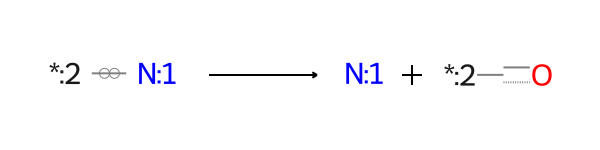

In [349]:
reactionsMol2['cyclicAmines']

# Create the Bonds 

In [202]:
bondsMols = {
    'urea': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]!@C'), Chem.MolFromSmarts('C!@[#7;+0;D2,D3:2]')],
    'ureaR': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]C'), Chem.MolFromSmarts('C[#7;+0;D2,D3:2]')],
    'amide': [Chem.MolFromSmarts('[C;!$(C([#7])[#7]):1]!@[#7;+0;!D1:3]')],
    'amideR': [Chem.MolFromSmarts('[C;!$(C([#7])[#7]):1][#7;+0;!D1:3]')],
    'ether': [Chem.MolFromSmarts('[O;+0]-!@[#6:2]')],
    'etherR': [Chem.MolFromSmarts('[O;+0;!r6;!r5]-[#6:2]')],
    'ester': [Chem.MolFromSmarts('[C:1]!@-[O;+0:3]')],
    #esterR': [Chem.MolFromSmarts('[C:1][O;+0:3]')],
    'amines': [Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-!@[*:1]'), Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-!@[*:2]')],
    'aminesR': [Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-[*:1]'), Chem.MolFromSmarts('[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])]-[*:2]')],
    'cyclicAmines': [Chem.MolFromSmarts('[#7;R;D3;+0:1]-!@[*:2]')],
    #'cyclicAminesR': [Chem.MolFromSmarts('[#7;R;D3;+0:1]-[*:2]')],
    'olefin': [Chem.MolFromSmarts('[C:1]=!@[C:2]')],
    'olefinR': [Chem.MolFromSmarts('[C:1]=[C:2]')],
    'arNalC': [Chem.MolFromSmarts('[c:1]-!@[c:2]')],
    'laNalC': [Chem.MolFromSmarts('[N;+0:1]-!@[C:2]')],
    'arCarC': [Chem.MolFromSmarts('[c:1]-!@[c:2]')],
    'arCarCR': [Chem.MolFromSmarts('[c:1]-[c:2]')],
    'arNarC': [Chem.MolFromSmarts('[n;+0:1]-!@[c:2]')],
    'arNarCR': [Chem.MolFromSmarts('[n;+0:1]-[c:2]')],
    'sulphonamide': [Chem.MolFromSmarts('[#7;+0;D2,D3:1]-!@[S:2]')]
    
}


for k, v in bondsMols.items():
    lst = []
    for molecule in v:
        Chem.GetSymmSSSR(molecule)
        lst.append(molecule)
    bondsMols[k] = lst
    
brokenBondsDefs = {k: [molecule.GetBonds()[0] for molecule in v] for k, v in bondsMols.items()}

# Create the atom mapping rules

In [210]:
aux = {ch:'O' for ch in allChars}
aux.update({'N': ''})
fillingAtoms = { 'ureaR':{'N':'', 'C':'O'},
                'urea':{'N':'', 'C':'O'},
                'amide': {'N': '', 'C': 'O'},
                'amideR': {'N': '', 'C': 'O'},
                'ester': {'O': '', 'C': 'O'},
                #'esterR': {'O': '', 'C': 'O'},
                'ether': {'O': '', 'C': 'O', 'c':'O'},
                'etherR': {'O': '', 'C': 'O', 'c':'O', 'o':''},
               'amines': {ch:'' for ch in allChars},
               'aminesR': {ch:'' for ch in allChars},
               'cyclicAmines':aux,
               #'cyclicAminesR': {ch:'O' for ch in allChars}.update({'N': ''}),
               'olefin': {'C': ''},
               'olefinR': {'C': ''},
               'arNalC': {'N': '', 'C': '', 'n': '', 'c': ''},
               'laNalC': {'N': '', 'C': '', 'n': '', 'c': ''},
               'arCarC': {'C': '', 'c': ''},
               'arCarCR': {'C': '', 'c': ''},
                'arNarC': {'C': '', 'c': '', 'N': '', 'n': ''},
               'arNarCR': {'C': '', 'c': '', 'N': '', 'n': ''},
               'sulphonamide': {'N': '', 'S': ''}}

# Testing

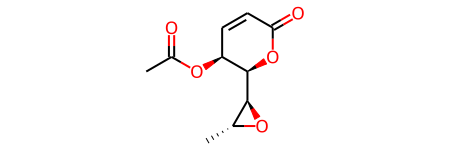

In [435]:
import random
idx = random.randint(0, len(mibig))
mol = list(mibig.values())[idx]
mol

In [436]:
Chem.MolToSmiles(mol)

'CC(=O)O[C@H]1C=CC(=O)O[C@H]1[C@H]1O[C@@H]1C'

In [437]:
fragmentator = geass.Geass(mol, brokenBondsDefs, reactants, fillingAtoms, BULnames, verbose=0)
fragmentator.get_bonds_to_break()
fragmentator.create_fragmentation_graph()

In [438]:
fragmentator.breakable_mol_bonds

{4: 'etherR', 0: 'etherR', 13: 'olefinR'}

In [439]:
fragmentator.plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

# Success analysis

In [122]:
start_from = 0
results = {}
success = {}
for j, (idx, mol) in enumerate(mibig.items()):
    print(f'Progress [{j}/{len(mibig)-1}]', end='\r')
    fragmentator = geass.Geass(mol, brokenBondsDefs, reactants, fillingAtoms, BULnames, verbose=0)
    fragmentator.get_bonds_to_break()
    fragmentator.create_fragmentation_graph()
    NPs = nx.get_node_attributes(fragmentator.graph, 'isNP')
    success[idx] = {'NP': len([node for node, isNP in NPs.items() if isNP == 'Yes']),
                 'NotNP': len([node for node, isNP in NPs.items() if isNP == 'No'])}
    results[idx] = fragmentator

No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.

No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.

[12:05:55] WARNING: not removing hydrogen atom without neighbors
[12:05:55] WARNING: not removing hydrogen atom without neighbors
[12:05:55] WARNING: not removing hydrogen atom without neighbors
[12:05:55] WARNING: not removing hydrogen atom without neighbors
[12:05:55] WARNING: not removing hydrogen atom without neighbors
[12:05:55] WARNING: not removing hydrogen atom without neighbors
[12:05:55] WARNING: not removing hydrogen atom without neighbors
[12:05:55] WARNING: not removing hydrogen atom without neighbors


No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.
No breakable bonds were found. Impossible to create the fragmentation graph.

[12:09:12] WARNING: not removing hydrogen atom without neighbors
[12:09:12] WARNING: not removing hydrogen atom without neighbors
[12:09:13] WARNING: not removing hydrogen atom without neighbors
[12:09:13] WARNING: not removing hydrogen atom without neighbors


In [123]:
red_compounds = []
for idx, fragmentator in results.items():
    NPs = nx.get_node_attributes(fragmentator.graph, 'isNP')
    red_nodes = [node for node, isNP in NPs.items() if isNP == 'No']
    smiles = nx.get_node_attributes(fragmentator.graph, 'SMILES')
    smiles = [smiles[node] for node in red_nodes]    
    red_compounds = red_compounds + smiles
print(len(red_compounds))

4418


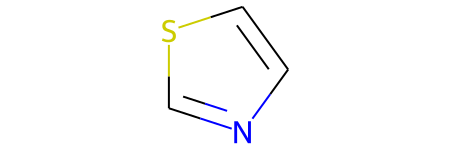

In [140]:
import random
idx = random.randint(0, len(red_compounds))
Chem.MolFromSmiles(red_compounds[idx])

In [177]:
def get_unique_cpds(cpds):
    '''
    for a list of rdkit molecules, return the unique structures and their frequency
    '''
    
    count = {0: {'molecule': cpds[0], 'count': 1.0}} # {index (int): {'molecule': (mol), 'count': (int)}}
    visited_molecules = {0: cpds[0]} # {index: (mol)}
    for i, cpd in enumerate(cpds[1:]):
        print(f'Progress: [{i+2}/{len(cpds)}]', end='\r')
        idx, flag = is_in(visited_molecules, cpd)
        if flag:
            # actualize the count
            count[idx]['count'] += 1.0
        else:
            # create an entry in the dictionary
            count[len(visited_molecules)] = {'molecule': cpd, 'count': 1.0}
            visited_molecules[len(visited_molecules)] = cpd
        
    return count

In [178]:
def is_in(ddd, mol):
    'Return whelther a molecule is in an indexed dictionary and where'
    for i, structure in ddd.items():
        # iterate over list
        if len(mol.GetSubstructMatch(structure, )) == mol.GetNumAtoms():
                # Match
                return i, True

    return None, False
    

In [179]:
red_mols = [Chem.MolFromSmiles(_) for _ in red_compounds]
count = get_unique_cpds(red_mols)

In [183]:
count_lst = list(count.values())

In [185]:
count_lst = sorted(count_lst, key=lambda i: -i['count'])
count_lst

[{'molecule': <rdkit.Chem.rdchem.Mol at 0x11c88daae00>, 'count': 672.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89eb2320>, 'count': 64.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89eab0a0>, 'count': 59.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89e6dcc0>, 'count': 57.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89f38e80>, 'count': 35.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c88de17e0>, 'count': 26.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89ea8dc0>, 'count': 26.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89f3a080>, 'count': 23.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89ea87c0>, 'count': 22.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c88de0e80>, 'count': 21.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89e6c340>, 'count': 21.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89e72d40>, 'count': 20.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c89ea81c0>, 'count': 19.0},
 {'molecule': <rdkit.Chem.rdchem.Mol at 0x11c88dab5e0>, 'count'



In [443]:
Chem.Draw.MolsToGridImage([x['molecule'] for x in count_lst[:200]],molsPerRow=4,subImgSize=(300,300), maxMols=500)

In [141]:
with open('red_list.pickle', 'wb') as f:
    pickle.dump(red_compounds, f)

In [444]:
with open('red_list_unique.pickle', 'wb') as f:
    pickle.dump(count_lst, f)

In [38]:
fragmented = len([k for k, v in success.items() if v['NotNP'] == 0])
print(f'Success rate: {fragmented/len(success)}' )

Success rate: 0.15921437526117843


In [39]:
rates = {k:v['NP']/(v['NP'] + v['NotNP']) for k, v in success.items() if v['NP'] + v['NotNP'] != 0}

In [27]:
import seaborn as sns

<AxesSubplot:ylabel='Count'>

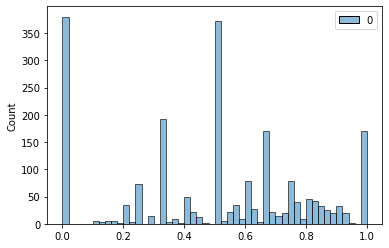

In [28]:
sns.histplot(rates.values(), bins = 50)

In [29]:
import numpy as np
np.mean(list(rates.values()))

0.4914791383476893